In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    GradientBoostingClassifier,
    StackingClassifier
)

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

In [ ]:
#Load data
data=pd.read_csv("wdbc.data", header=None)
data.columns=[
    "id", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

X=data.drop(columns=["id", "diagnosis"])
y=data["diagnosis"].map({"M": 0, "B": 1})

#Dataset info
print("Dataset shape:", X.shape)
print("\nNumber of features:", X.shape[1])
print("\nNumber of samples:", X.shape[0])
print("\nTarget classes: Malignant (M), Benign (B)")
print("\nFirst 5 rows:")
display(X.head())
print("\nDataset Information:")
X.info()
print("\nMissing Values:")
print(X.isnull().sum().sum())
print("\nClass Distribution:")
print(y.value_counts())

Dataset shape: (569, 30)

Number of features: 30

Number of samples: 569

Target classes: Malignant (M), Benign (B)

First 5 rows:


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   radius_mean              569 non-null    float64
 1   texture_mean             569 non-null    float64
 2   perimeter_mean           569 non-null    float64
 3   area_mean                569 non-null    float64
 4   smoothness_mean          569 non-null    float64
 5   compactness_mean         569 non-null    float64
 6   concavity_mean           569 non-null    float64
 7   concave_points_mean      569 non-null    float64
 8   symmetry_mean            569 non-null    float64
 9   fractal_dimension_mean   569 non-null    float64
 10  radius_se                569 non-null    float64
 11  texture_se               569 non-null    float64
 12  perimeter_se             569 non-null    float64
 13  area_se                  569 non-null    float64
 14  smoo

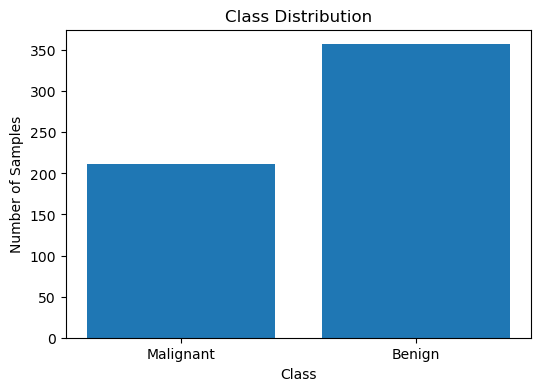

In [ ]:
#Class Distribution
class_counts=y.value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Malignant","Benign"],class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution")
plt.show()

#Feature distribution
X.hist(figsize=(16, 12),bins=20)
plt.tight_layout()
plt.show()

#Correlation heatmap
plt.figure(figsize=(14, 10))
plt.imshow(X.corr(),cmap="coolwarm",aspect="auto")
plt.colorbar()
plt.xticks(range(len(X.columns)),X.columns,rotation=90,fontsize=6)
plt.yticks(range(len(X.columns)),X.columns,fontsize=6)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
#Train Test split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:",X_train.shape[0])
print("\nTesting samples:",X_test.shape[0])

Training samples: 455

Testing samples: 114


In [ ]:
#Bagging model
bagging=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),random_state=42)
bagging_params={"n_estimators": [3, 10, 20],"max_samples": [0.7, 1.0],"max_features": [0.7, 1.0]}
bagging_grid=GridSearchCV(bagging,bagging_params,cv=5,scoring="accuracy",n_jobs=-1)
bagging_grid.fit(X_train, y_train)
print("Best Bagging Parameters:")
print(bagging_grid.best_params_)
print("\nBest CV Accuracy:", bagging_grid.best_score_)

Best Bagging Parameters:
{'max_features': 0.7, 'max_samples': 1.0, 'n_estimators': 20}

Best CV Accuracy: 0.956043956043956


In [ ]:
#Bagging Hyperparameter results
bagging_results=pd.DataFrame(bagging_grid.cv_results_)
bagging_table=bagging_results[["param_n_estimators","param_max_samples","param_max_features","mean_test_score"]].copy()
bagging_table["Avg CV Accuracy (%)"]=(bagging_table["mean_test_score"]*100)

bagging_f1_scores=[]
for params in bagging_results["params"]:
    model=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),random_state=42,**params)
    scores=[]

    for train_index, val_index in __import__("sklearn").model_selection.StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42).split(X_train, y_train):

        model.fit(X_train.iloc[train_index],y_train.iloc[train_index])
        predictions=model.predict(X_train.iloc[val_index])
        scores.append(f1_score(y_train.iloc[val_index],predictions))

    bagging_f1_scores.append(np.mean(scores) * 100)

bagging_table["Avg CV F1 Score"]=bagging_f1_scores
bagging_table[["param_n_estimators","param_max_samples","param_max_features","Avg CV Accuracy (%)","Avg CV F1 Score"]]

,param_n_estimators,param_max_samples,param_max_features,Avg CV Accuracy (%),Avg CV F1 Score
0,3,0.7,0.7,93.846154,96.636921
1,10,0.7,0.7,94.285714,95.901339
2,20,0.7,0.7,94.505495,95.562759
3,3,1.0,0.7,93.846154,95.810593
4,10,1.0,0.7,95.384615,96.479952
5,20,1.0,0.7,95.604396,96.659467
6,3,0.7,1.0,93.406593,93.946268
7,10,0.7,1.0,92.967033,96.113870
8,20,0.7,1.0,94.285714,95.567097
9,3,1.0,1.0,92.527473,95.026689


In [ ]:
#Boosting- Gradient Boosting
gradient_boosting=GradientBoostingClassifier(random_state=42)
gradient_params={"n_estimators": [50, 100, 150],"learning_rate": [0.01, 0.1, 0.2],"max_depth": [1, 2, 3]}
gradient_grid=GridSearchCV(gradient_boosting,gradient_params,cv=5,scoring="accuracy",n_jobs=-1)
gradient_grid.fit(X_train, y_train)
print("Best Gradient Boosting Parameters:")
print(gradient_grid.best_params_)
print("Best CV Accuracy:", gradient_grid.best_score_)

Best Gradient Boosting Parameters:
{'learning_rate': 0.2, 'max_depth': 1, 'n_estimators': 100}
Best CV Accuracy: 0.9802197802197803


In [ ]:
#Boosting hyperparameter results
gradient_results=pd.DataFrame(gradient_grid.cv_results_)
gradient_table=gradient_results[["param_n_estimators","param_learning_rate","param_max_depth","mean_test_score"]].copy()
gradient_table["Avg CV Accuracy (%)"]=(gradient_table["mean_test_score"]*100)
gradient_f1_scores=[]

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
for params in gradient_results["params"]:
    model=GradientBoostingClassifier(random_state=42,**params)
    scores=[]

    for train_index, val_index in cv.split(X_train, y_train):
        model.fit(X_train.iloc[train_index],y_train.iloc[train_index])
        predictions=model.predict(X_train.iloc[val_index])
        scores.append(f1_score(y_train.iloc[val_index],predictions))

    gradient_f1_scores.append(np.mean(scores)*100)

gradient_table["Avg CV F1 Score"]=gradient_f1_scores
gradient_table[["param_n_estimators","param_learning_rate","param_max_depth","Avg CV Accuracy (%)","Avg CV F1 Score"]]

,param_n_estimators,param_learning_rate,param_max_depth,Avg CV Accuracy (%),Avg CV F1 Score
0,50,0.01,1,89.230769,92.018832
1,100,0.01,1,90.769231,93.606333
2,150,0.01,1,92.967033,94.195327
3,50,0.01,2,93.626374,95.521086
4,100,0.01,2,94.505495,95.317909
5,150,0.01,2,94.725275,95.107358
6,50,0.01,3,92.967033,94.970266
7,100,0.01,3,94.505495,95.309091
8,150,0.01,3,94.065934,95.809821
9,50,0.10,1,95.824176,95.468412


In [ ]:
#Stacking preparation
svm_model=Pipeline([("scaler", StandardScaler()),("svm", SVC(probability=True, random_state=42))])
nb_model=GaussianNB()
dt_model=DecisionTreeClassifier(random_state=42,max_depth=3)
base_models=[("svm", svm_model),("naive_bayes", nb_model),("decision_tree", dt_model)]
meta_learner=LogisticRegression(max_iter=1000,random_state=42)

In [ ]:
#Stacking model
stacking=StackingClassifier(estimators=base_models,final_estimator=meta_learner,cv=5)
stacking_params={"final_estimator__C": [0.1, 1.0, 10.0]}
stacking_grid=GridSearchCV(stacking,stacking_params,cv=5,scoring="accuracy",n_jobs=-1)
stacking_grid.fit(X_train, y_train)
print("Best Stacking Parameters:")
print(stacking_grid.best_params_)
print("Best CV Accuracy:", stacking_grid.best_score_)

Best Stacking Parameters:
{'final_estimator__C': 10.0}
Best CV Accuracy: 0.9692307692307693


In [ ]:
#Stacking evaluation
stacking_results=pd.DataFrame(stacking_grid.cv_results_)
stacking_f1_scores=[]

for params in stacking_results["params"]:
    model=StackingClassifier(estimators=base_models,final_estimator=LogisticRegression(max_iter=1000,random_state=42,
            C=params["final_estimator__C"]),cv=5)
    scores=[]

    for train_index, val_index in cv.split(X_train, y_train):
        model.fit(X_train.iloc[train_index],y_train.iloc[train_index])
        predictions=model.predict(X_train.iloc[val_index])
        scores.append(f1_score(y_train.iloc[val_index],predictions))

    stacking_f1_scores.append(np.mean(scores)*100)

stacking_table=pd.DataFrame({"Base Models": ["SVM + Naive Bayes + Decision Tree"] * len(stacking_results),
    "Meta Learner": ["Logistic Regression"] * len(stacking_results),
    "C": [params["final_estimator__C"]for params in stacking_results["params"]],
    "Avg CV Accuracy (%)": stacking_results["mean_test_score"] * 100,
    "Avg CV F1 Score": stacking_f1_scores})

stacking_table

,Base Models,Meta Learner,C,Avg CV Accuracy (%),Avg CV F1 Score
0,SVM + Naive Bayes + Decision Tree,Logistic Regression,0.1,95.384615,96.688329
1,SVM + Naive Bayes + Decision Tree,Logistic Regression,1.0,96.483516,97.021151
2,SVM + Naive Bayes + Decision Tree,Logistic Regression,10.0,96.923077,97.543264


In [ ]:
#Best Models
best_bagging=bagging_grid.best_estimator_
best_gradient=gradient_grid.best_estimator_
best_stacking=stacking_grid.best_estimator_
print("Best Bagging:")
print(bagging_grid.best_params_)
print("\nBest Gradient Boosting:")
print(gradient_grid.best_params_)
print("\nBest Stacking:")
print(stacking_grid.best_params_)

Best Bagging:
{'max_features': 0.7, 'max_samples': 1.0, 'n_estimators': 20}

Best Gradient Boosting:
{'learning_rate': 0.2, 'max_depth': 1, 'n_estimators': 100}

Best Stacking:
{'final_estimator__C': 10.0}


In [ ]:
#Train best models
best_bagging.fit(X_train,y_train)
best_gradient.fit(X_train,y_train)
best_stacking.fit(X_train,y_train)

#Predictions
models={"Bagging": best_bagging,"Gradient Boosting": best_gradient,"Stacked Ensemble": best_stacking}
predictions={}
for name, model in models.items():
    predictions[name]=model.predict(X_test)
print("Predictions generated.")

Predictions generated.


In [ ]:
#Performance Comparison
performance=[]
for name, model in models.items():
    y_pred=predictions[name]
    performance.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
        "Precision (%)": precision_score(y_test, y_pred) * 100,
        "Recall (%)": recall_score(y_test, y_pred) * 100,
        "F1 Score (%)": f1_score(y_test, y_pred) * 100})

performance_table=pd.DataFrame(performance)
performance_table

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Bagging,93.859649,95.774648,94.444444,95.104895
1,Gradient Boosting,96.491228,95.945946,98.611111,97.260274
2,Stacked Ensemble,98.245614,98.611111,98.611111,98.611111


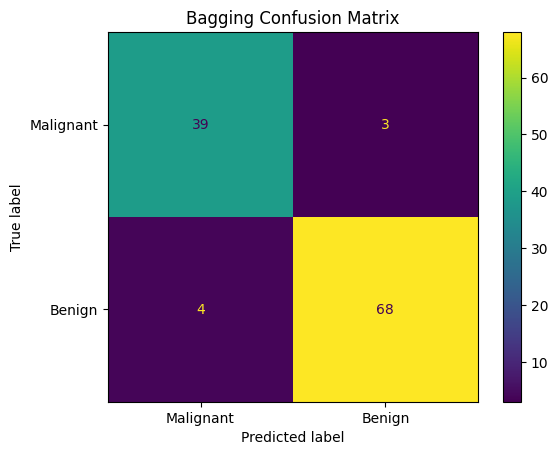

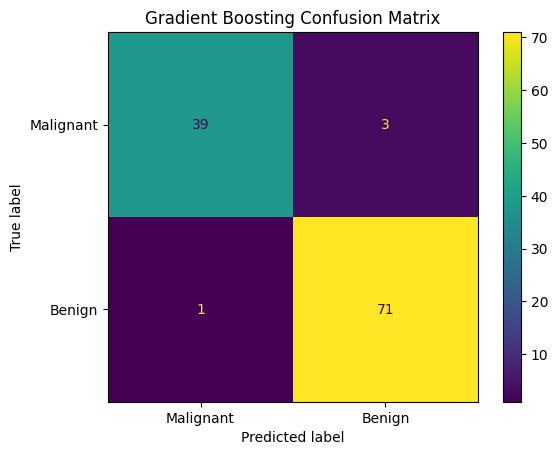

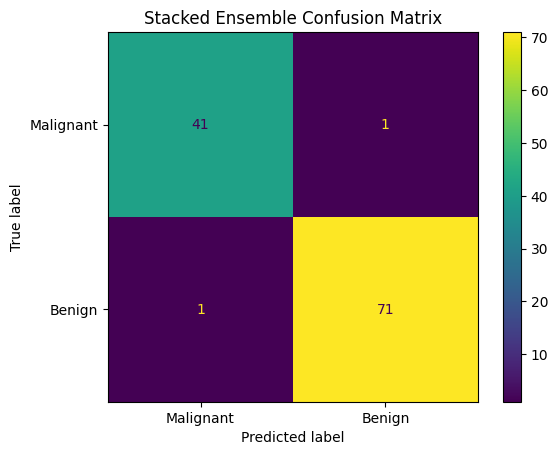

In [ ]:
#Confusion Matrices
for name, model in models.items():
    y_pred=predictions[name]
    cm=confusion_matrix(y_test, y_pred)
    display=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Malignant", "Benign"])
    display.plot()
    plt.title(name +" Confusion Matrix")
    plt.show()

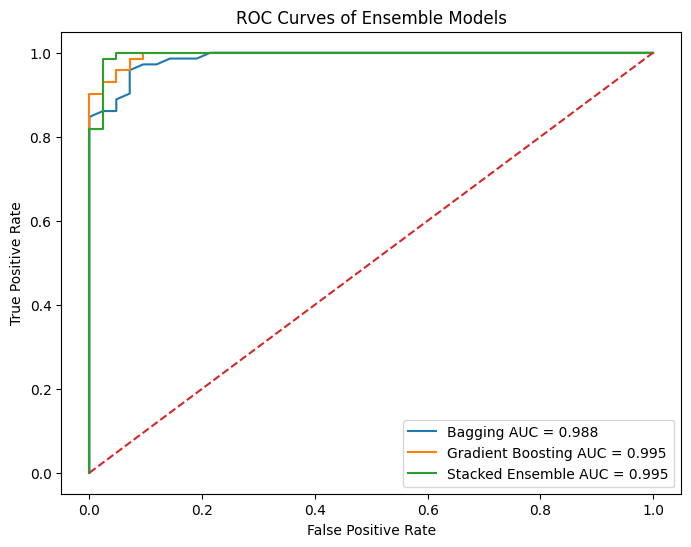

,Model,AUC
0,Bagging,0.987930
1,Gradient Boosting,0.994709
2,Stacked Ensemble,0.995370


In [ ]:
#ROC Curves and AUC Values
plt.figure(figsize=(8, 6))

for name, model in models.items():
    probabilities =model.predict_proba(X_test)[:, 1]
    fpr,tpr,thresholds=roc_curve(y_test,probabilities)
    auc=roc_auc_score(y_test,probabilities)
    plt.plot(fpr,tpr,label=name + " AUC = " + str(round(auc, 3)))

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves of Ensemble Models")
plt.legend()
plt.show()

auc_results=[]
for name, model in models.items():
    probabilities=model.predict_proba(X_test)[:, 1]
    auc=roc_auc_score(y_test,probabilities)
    auc_results.append({"Model": name,"AUC": auc})

auc_table=pd.DataFrame(auc_results)
auc_table

In [ ]:
#Cross validation test perfomance
comparison = pd.DataFrame({"Model": ["Bagging","Gradient Boosting","Stacked Ensemble"],
    "CV Accuracy (%)": [
        bagging_grid.best_score_ * 100,
        gradient_grid.best_score_ * 100,
        stacking_grid.best_score_ * 100
    ],
    "Test Accuracy (%)": [
        accuracy_score(y_test, predictions["Bagging"]) * 100,
        accuracy_score(y_test, predictions["Gradient Boosting"]) * 100,
        accuracy_score(y_test, predictions["Stacked Ensemble"]) * 100]})
comparison

#Best Model
best_model_name=performance_table.loc[performance_table["Accuracy (%)"].idxmax(),"Model"]
best_accuracy=performance_table["Accuracy (%)"].max()
print("Best Model:", best_model_name)
print("Test Accuracy:", round(best_accuracy, 2), "%")

Best Model: Stacked Ensemble
Test Accuracy: 98.25 %
